# Month 2 — Week 1: Data Visualization
**Name:** Areej Suleman  
**Registration number:** FA23-BAI-018  
**GitHub:** Areej-Suleman


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.lines import Line2D

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 13})

tips = sns.load_dataset("tips")
flights = sns.load_dataset("flights")
mpg = sns.load_dataset("mpg")
penguins = sns.load_dataset("penguins")
titanic = sns.load_dataset("titanic")

print("Datasets loaded:")
for name, data in [("tips", tips), ("flights", flights), ("mpg", mpg),
                   ("penguins", penguins), ("titanic", titanic)]:
    print(f"{name}: {len(data)} rows")

Datasets loaded:
tips: 244 rows
flights: 144 rows
mpg: 398 rows
penguins: 344 rows
titanic: 891 rows


# Part 1 — Matplotlib

## 1. Line plot — monthly passengers

Dataset: flights. Plot one year with markers, labels and a grid.

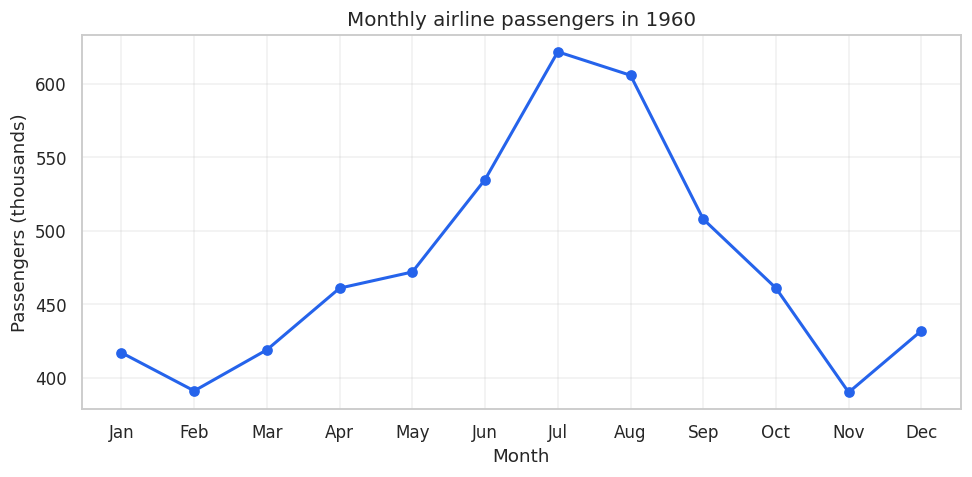

In [2]:
year = 1960
one_year = flights.loc[flights["year"] == year].copy()
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(one_year["month"].astype(str), one_year["passengers"],
        color="#2563eb", marker="o", linewidth=2)
ax.set(title=f"Monthly airline passengers in {year}",
       xlabel="Month", ylabel="Passengers (thousands)")
ax.grid(True, alpha=0.3)
fig.tight_layout()
plt.show()

**What does this chart tell us?**

Passenger numbers rise toward the middle of 1960 and peak in July, then fall toward November. This suggests seasonal demand, with more passengers during the summer months.

## 2. Bar chart — average bill by day

Dataset: tips. Use custom colors and value labels.

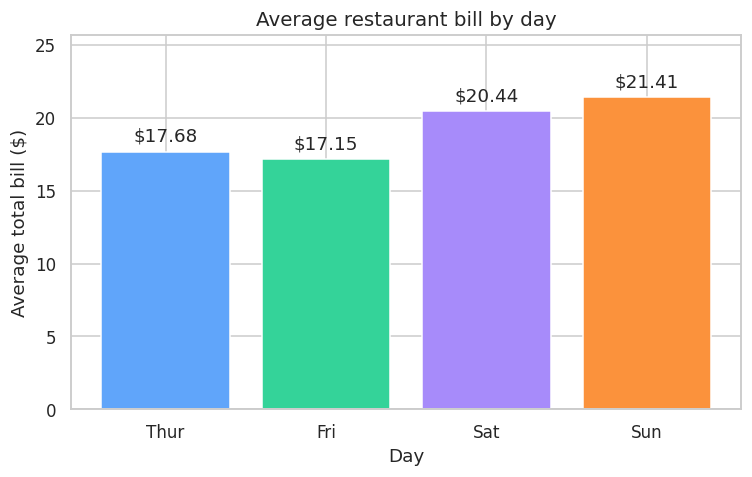

In [3]:
day_order = ["Thur", "Fri", "Sat", "Sun"]
average_bill = tips.groupby("day", observed=True)["total_bill"].mean().reindex(day_order)
fig, ax = plt.subplots(figsize=(7, 4.5))
bars = ax.bar(average_bill.index, average_bill.values,
              color=["#60a5fa", "#34d399", "#a78bfa", "#fb923c"])
ax.bar_label(bars, fmt="$%.2f", padding=4)
ax.set(title="Average restaurant bill by day", xlabel="Day", ylabel="Average total bill ($)")
ax.set_ylim(0, average_bill.max() * 1.2)
fig.tight_layout()
plt.show()

**What does this chart tell us?**

Sunday has the highest average bill (about $21.41), while Friday has the lowest (about $17.15). These are averages per recorded bill, not total revenue for each day.

## 3. Horizontal bar chart — fuel economy

Dataset: mpg. Sort average mpg by cylinders from highest to lowest.

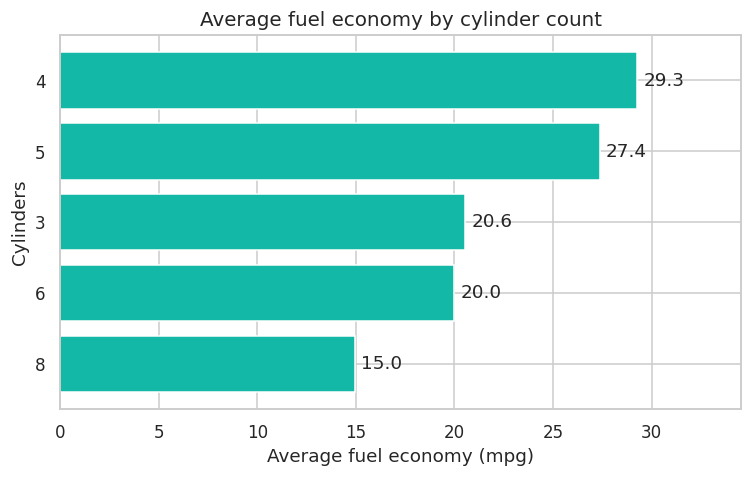

In [4]:
average_mpg = mpg.groupby("cylinders")["mpg"].mean().sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(7, 4.5))
bars = ax.barh(average_mpg.index.astype(str), average_mpg.values, color="#14b8a6")
ax.invert_yaxis()  # Highest average appears at the top.
ax.bar_label(bars, fmt="%.1f", padding=4)
ax.set(title="Average fuel economy by cylinder count", xlabel="Average fuel economy (mpg)", ylabel="Cylinders")
ax.set_xlim(0, average_mpg.max() * 1.18)
fig.tight_layout()
plt.show()

**What does this chart tell us?**

Four-cylinder cars have the highest average fuel economy, while eight-cylinder cars have the lowest. The pattern is not perfectly monotonic: three-cylinder cars do not have the highest average mpg.

## 4. Histograms — compare bin counts

Dataset: tips. Show 10, 20 and 30 bins side by side, with mean and median lines.

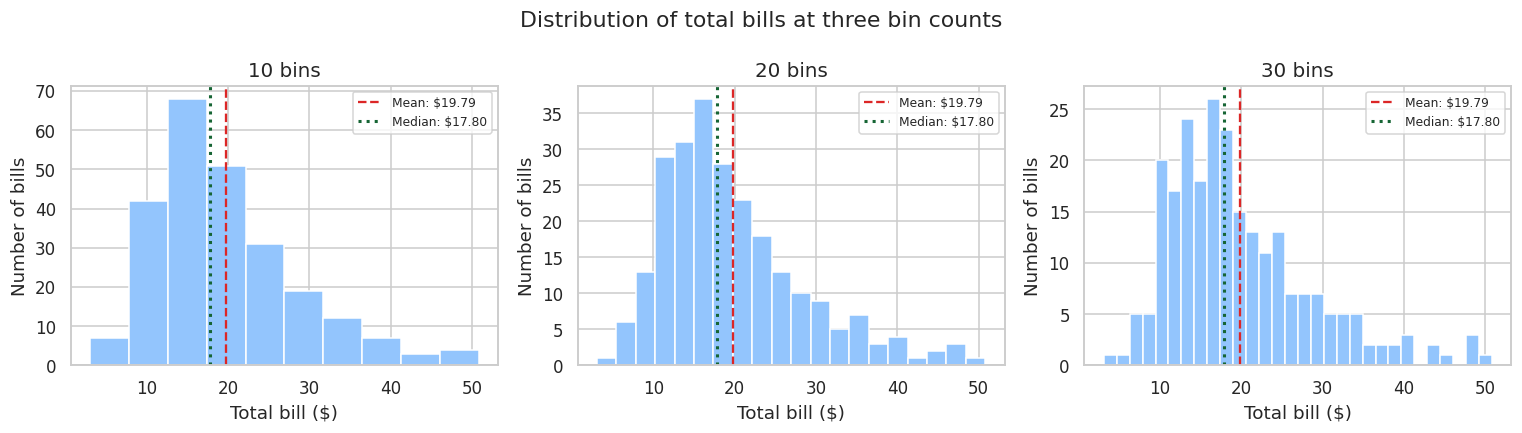

In [5]:
mean_bill = tips["total_bill"].mean()
median_bill = tips["total_bill"].median()
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharex=True)
for ax, bins in zip(axes, [10, 20, 30]):
    ax.hist(tips["total_bill"], bins=bins, color="#93c5fd", edgecolor="white")
    ax.axvline(mean_bill, color="#dc2626", linestyle="--", label=f"Mean: ${mean_bill:.2f}")
    ax.axvline(median_bill, color="#166534", linestyle=":", linewidth=2, label=f"Median: ${median_bill:.2f}")
    ax.set(title=f"{bins} bins", xlabel="Total bill ($)", ylabel="Number of bills")
    ax.legend(fontsize=8)
fig.suptitle("Distribution of total bills at three bin counts")
fig.tight_layout()
plt.show()

**What does this chart tell us?**

All three plots show a right-skewed distribution: most bills are modest, with a few much larger bills. The mean ($19.79) exceeds the median ($17.80); more bins show finer detail but make the shape less smooth.

## 5. Scatter plot — weight and fuel economy

Dataset: mpg. Color represents origin; marker area represents horsepower. Rows missing these variables are excluded.

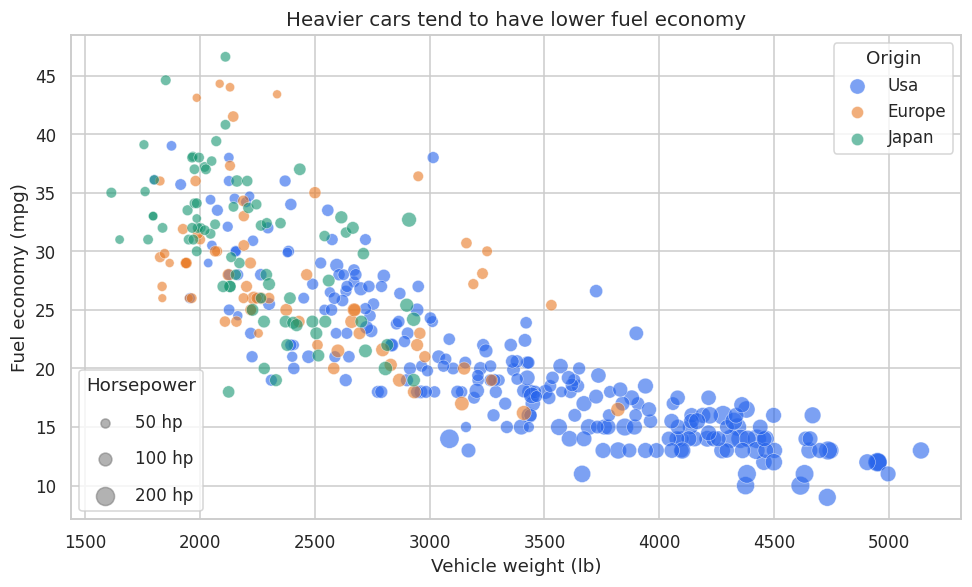

In [6]:
cars = mpg.dropna(subset=["weight", "mpg", "horsepower", "origin"])
origin_colors = {"usa": "#2563eb", "europe": "#e87924", "japan": "#159570"}
fig, ax = plt.subplots(figsize=(9, 5.5))
for origin, color in origin_colors.items():
    group = cars[cars["origin"] == origin]
    ax.scatter(group["weight"], group["mpg"], s=group["horsepower"] * 0.7,
               color=color, alpha=0.6, edgecolors="white", linewidth=0.4, label=origin.title())
origin_legend = ax.legend(title="Origin", loc="upper right")
ax.add_artist(origin_legend)
size_handles = [ax.scatter([], [], s=hp * 0.7, color="gray", alpha=0.6, label=f"{hp} hp")
                for hp in [50, 100, 200]]
ax.legend(handles=size_handles, title="Horsepower", loc="lower left", labelspacing=1.1)
ax.set(title="Heavier cars tend to have lower fuel economy", xlabel="Vehicle weight (lb)", ylabel="Fuel economy (mpg)")
fig.tight_layout()
plt.show()

**What does this chart tell us?**

Heavier cars generally have lower mpg, and larger markers show that many heavier cars also have more horsepower. Japanese and European cars tend to cluster toward lower weights, though the origin groups overlap.

## 6. Donut chart — smoking status

Dataset: tips. Show smoker and non-smoker shares with percentages.

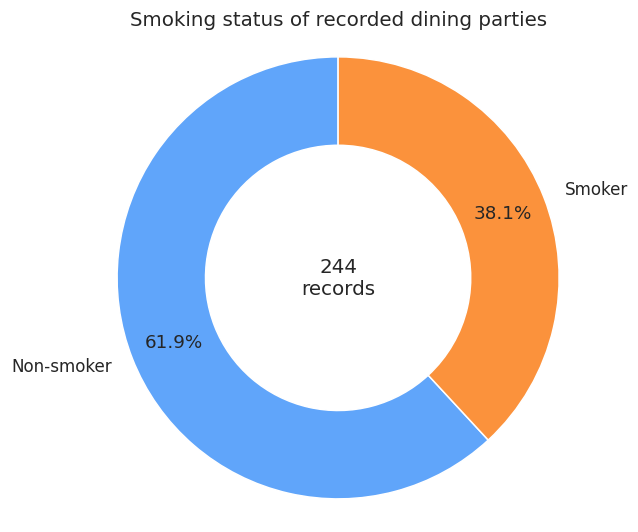

In [7]:
smoking_counts = tips["smoker"].value_counts().reindex(["No", "Yes"])
fig, ax = plt.subplots(figsize=(6, 5))
ax.pie(smoking_counts, labels=["Non-smoker", "Smoker"], autopct="%1.1f%%",
       colors=["#60a5fa", "#fb923c"], startangle=90, pctdistance=0.8,
       wedgeprops={"width": 0.4, "edgecolor": "white"})
ax.set_title("Smoking status of recorded dining parties")
ax.text(0, 0, f"{smoking_counts.sum()}\nrecords", ha="center", va="center", fontsize=13)
ax.axis("equal")  # A donut uses category labels rather than numeric axes.
fig.tight_layout()
plt.show()

**What does this chart tell us?**

Non-smoking parties account for about 61.9% of the recorded bills, compared with 38.1% for smoking parties. These proportions describe this restaurant sample, not the general population.

## 7. Mini dashboard — four plots

Combine four earlier plots into a 2 × 2 dashboard. Use tight_layout() and save a PNG at dpi=300.

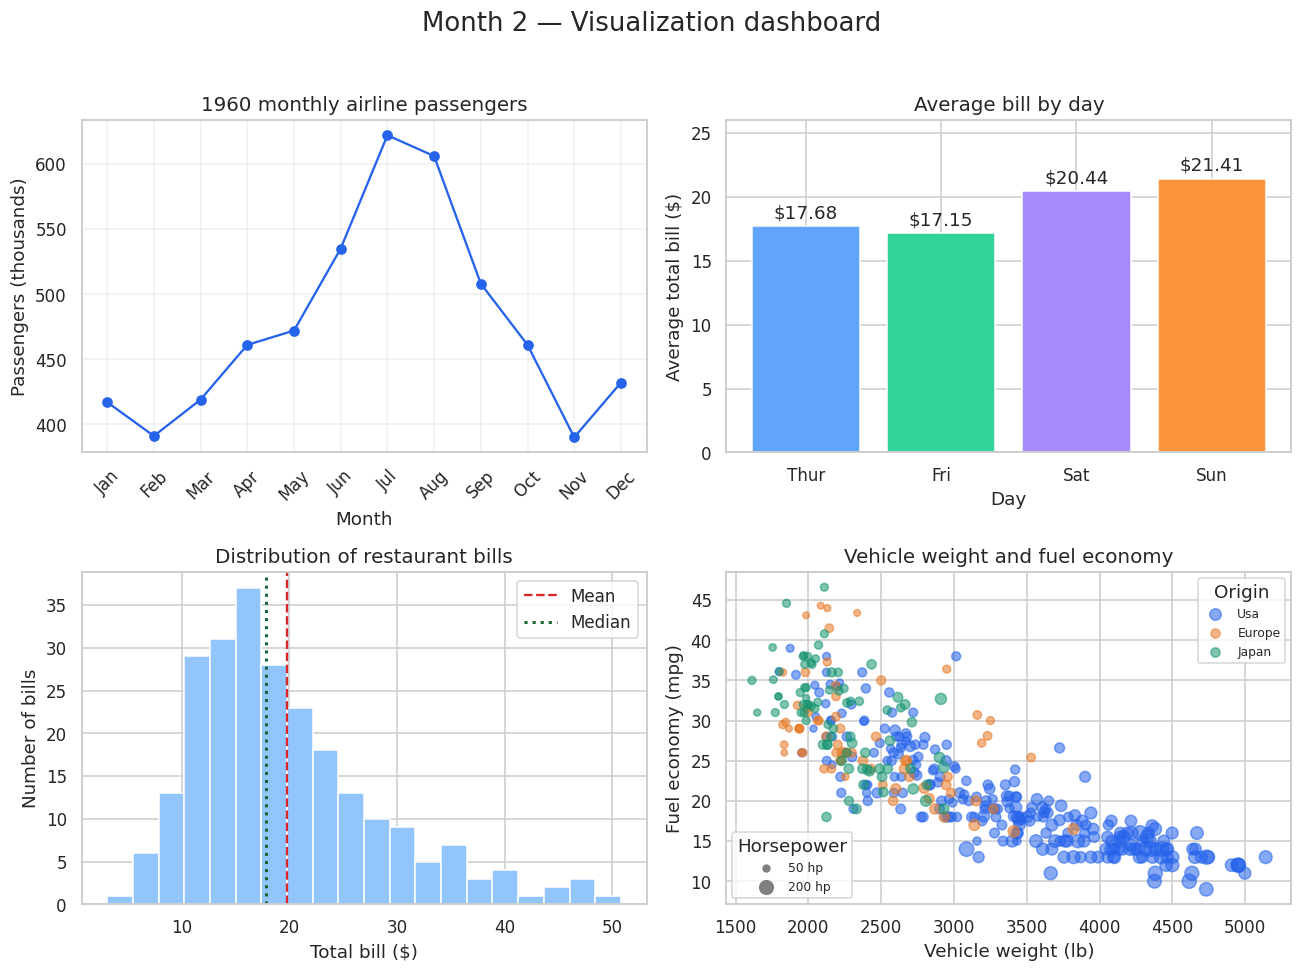

Saved: mini_dashboard.png (300 dpi)


In [8]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
ax = axes[0, 0]
ax.plot(one_year["month"].astype(str), one_year["passengers"], marker="o", color="#2563eb")
ax.set(title="1960 monthly airline passengers", xlabel="Month", ylabel="Passengers (thousands)")
ax.tick_params(axis="x", rotation=45)
ax.grid(True, alpha=0.3)

ax = axes[0, 1]
bars = ax.bar(average_bill.index, average_bill.values, color=["#60a5fa", "#34d399", "#a78bfa", "#fb923c"])
ax.bar_label(bars, fmt="$%.2f", padding=3)
ax.set(title="Average bill by day", xlabel="Day", ylabel="Average total bill ($)", ylim=(0, 26))

ax = axes[1, 0]
ax.hist(tips["total_bill"], bins=20, color="#93c5fd", edgecolor="white")
ax.axvline(mean_bill, color="#dc2626", linestyle="--", label="Mean")
ax.axvline(median_bill, color="#166534", linestyle=":", linewidth=2, label="Median")
ax.set(title="Distribution of restaurant bills", xlabel="Total bill ($)", ylabel="Number of bills")
ax.legend()

ax = axes[1, 1]
for origin, color in origin_colors.items():
    group = cars[cars["origin"] == origin]
    ax.scatter(group["weight"], group["mpg"], color=color, s=group["horsepower"] * 0.4,
               alpha=0.55, label=origin.title())
ax.set(title="Vehicle weight and fuel economy", xlabel="Vehicle weight (lb)", ylabel="Fuel economy (mpg)")
legend = ax.legend(title="Origin", fontsize=8, loc="upper right")
ax.add_artist(legend)
handles = [ax.scatter([], [], s=hp * 0.4, color="gray", label=f"{hp} hp") for hp in [50, 200]]
ax.legend(handles=handles, title="Horsepower", fontsize=8, loc="lower left")

fig.suptitle("Month 2 — Visualization dashboard", fontsize=17)
fig.tight_layout(rect=[0, 0, 1, 0.96])
fig.savefig("mini_dashboard.png", dpi=300, bbox_inches="tight")
plt.show()
print("Saved: mini_dashboard.png (300 dpi)")

**What does this chart tell us?**

The top-left plot shows a summer passenger peak; the top-right shows that Sunday has the highest average bill. The bottom-left shows right-skewed bills, while the bottom-right shows that heavier cars tend to have lower fuel economy.

# Part 2 — Seaborn

## 1. Countplot — Titanic passenger class

Dataset: titanic. Set hue to sex.

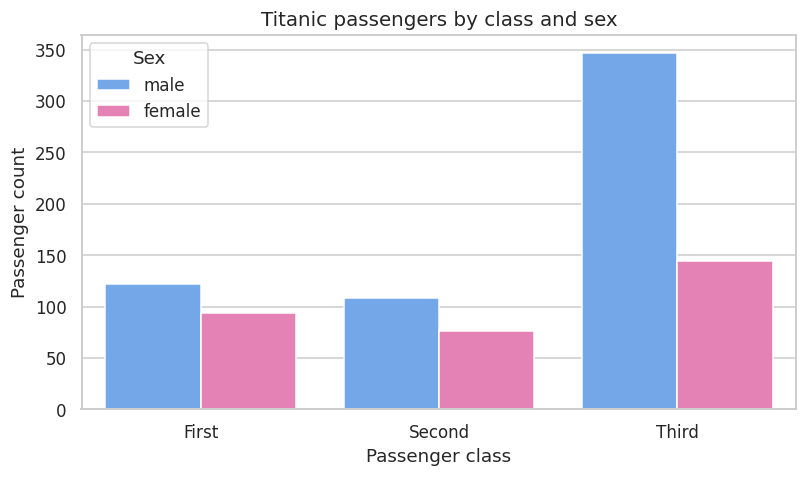

In [9]:
fig, ax = plt.subplots(figsize=(7.5, 4.5))
sns.countplot(data=titanic, x="class", hue="sex", order=["First", "Second", "Third"],
              palette={"male": "#60a5fa", "female": "#f472b6"}, ax=ax)
ax.set(title="Titanic passengers by class and sex", xlabel="Passenger class", ylabel="Passenger count")
ax.legend(title="Sex")
fig.tight_layout()
plt.show()

**What does this chart tell us?**

Third class contains the largest number of passengers, especially men. Men outnumber women in each class in this dataset.

## 2. Histogram with KDE — flipper lengths

Dataset: penguins. Use histplot(kde=True) with a separate color for each species.

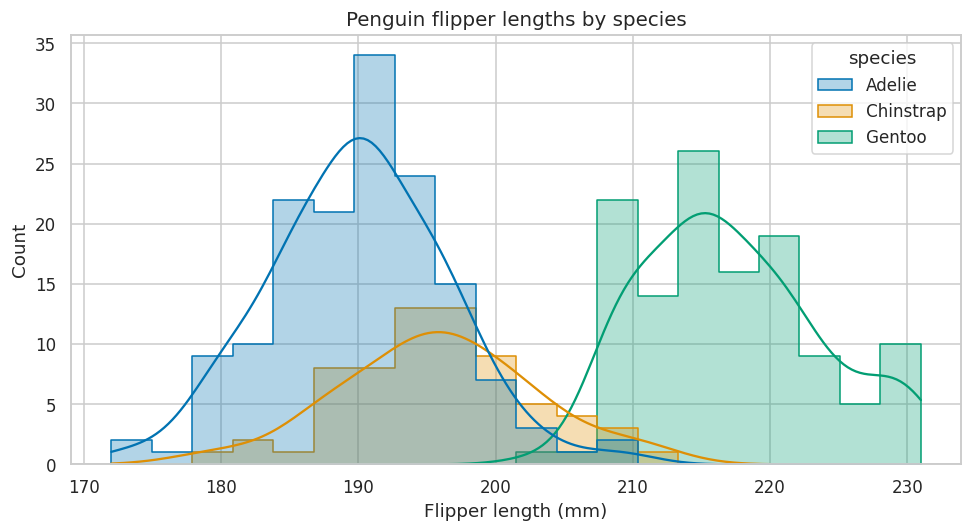

In [10]:
flipper_data = penguins.dropna(subset=["flipper_length_mm", "species"])
fig, ax = plt.subplots(figsize=(9, 5))
sns.histplot(data=flipper_data, x="flipper_length_mm", hue="species", kde=True,
             bins=20, element="step", alpha=0.3, palette="colorblind", ax=ax)
ax.set(title="Penguin flipper lengths by species", xlabel="Flipper length (mm)", ylabel="Count")
fig.tight_layout()
plt.show()

**What does this chart tell us?**

Gentoo penguins generally have longer flippers than Adelie and Chinstrap penguins. The Adelie and Chinstrap distributions overlap substantially, so flipper length alone does not separate all species.

## 3. Box versus violin — body mass

Dataset: penguins. Compare both plot types side by side and explain which shows more.

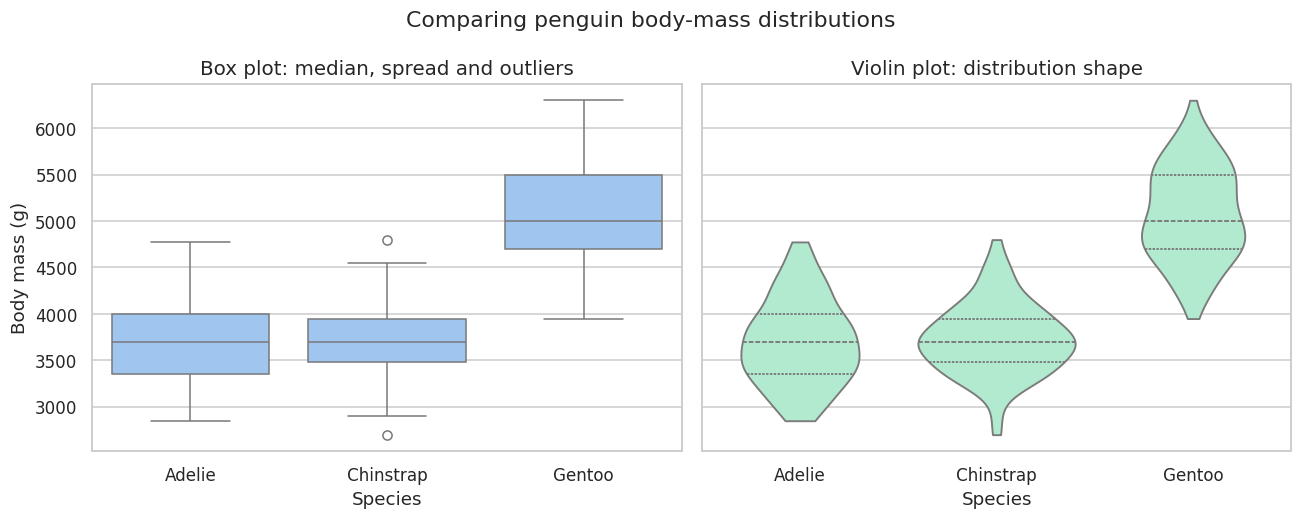

In [11]:
mass_data = penguins.dropna(subset=["body_mass_g", "species"])
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), sharey=True)
sns.boxplot(data=mass_data, x="species", y="body_mass_g", color="#93c5fd", ax=axes[0])
sns.violinplot(data=mass_data, x="species", y="body_mass_g", color="#a7f3d0", inner="quartile", cut=0, ax=axes[1])
for ax, title in zip(axes, ["Box plot: median, spread and outliers", "Violin plot: distribution shape"]):
    ax.set(title=title, xlabel="Species", ylabel="Body mass (g)")
fig.suptitle("Comparing penguin body-mass distributions")
fig.tight_layout()
plt.show()

**What does this chart tell us?**

The box plot makes the median, quartiles and potential outliers easy to compare; Gentoo penguins are generally heavier.  
The violin plot shows more detail about distribution shape and where observations are concentrated, although its density shape depends on smoothing.

## 4. Scatterplot — penguin bill dimensions

Dataset: penguins. Use hue=species and style=sex. Place bill length on x and bill depth on y.

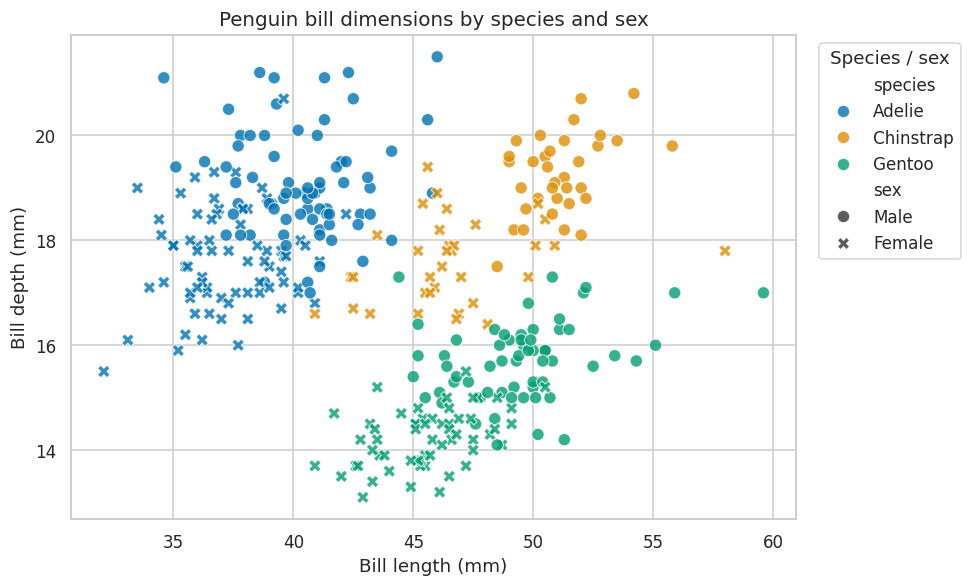

In [12]:
bill_data = penguins.dropna(subset=["bill_length_mm", "bill_depth_mm", "species", "sex"])
fig, ax = plt.subplots(figsize=(9, 5.5))
sns.scatterplot(data=bill_data, x="bill_length_mm", y="bill_depth_mm", hue="species", style="sex",
                 palette="colorblind", alpha=0.8, s=65, ax=ax)
ax.set(title="Penguin bill dimensions by species and sex", xlabel="Bill length (mm)", ylabel="Bill depth (mm)")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", title="Species / sex")
fig.tight_layout()
plt.show()

**What does this chart tell us?**

Adelie penguins tend to have shorter bills, while Gentoo penguins tend to have shallower bills than Chinstrap penguins at similar bill lengths. Male and female points overlap, so bill dimensions do not perfectly distinguish sex.

## 5. Heatmap — numeric correlations

Dataset: penguins. Use annot=True and a diverging colormap.

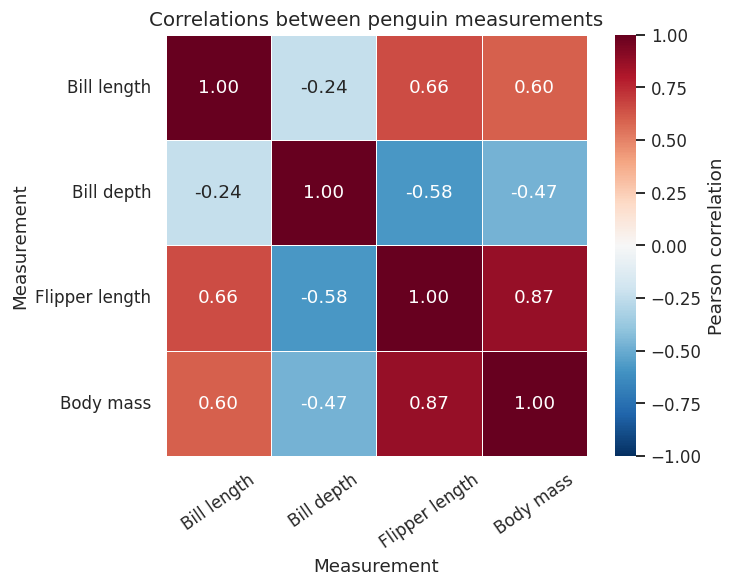

In [13]:
numeric_columns = penguins.select_dtypes(include="number")
correlations = numeric_columns.corr()  # Pearson correlation; pairwise non-missing values.
labels = ["Bill length", "Bill depth", "Flipper length", "Body mass"]
fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(correlations, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1,
             square=True, linewidths=0.5, xticklabels=labels, yticklabels=labels,
             cbar_kws={"label": "Pearson correlation"}, ax=ax)
ax.set(title="Correlations between penguin measurements", xlabel="Measurement", ylabel="Measurement")
ax.tick_params(axis="x", rotation=35)
ax.tick_params(axis="y", rotation=0)
fig.tight_layout()
plt.show()

**What does this chart tell us?**

Flipper length and body mass have a strong positive correlation (about 0.87): larger penguins tend to have longer flippers. These pooled correlations combine species and do not establish cause and effect.

## 6. Pairplot — relationships between measurements

Dataset: penguins. Set hue=species and give three insights.

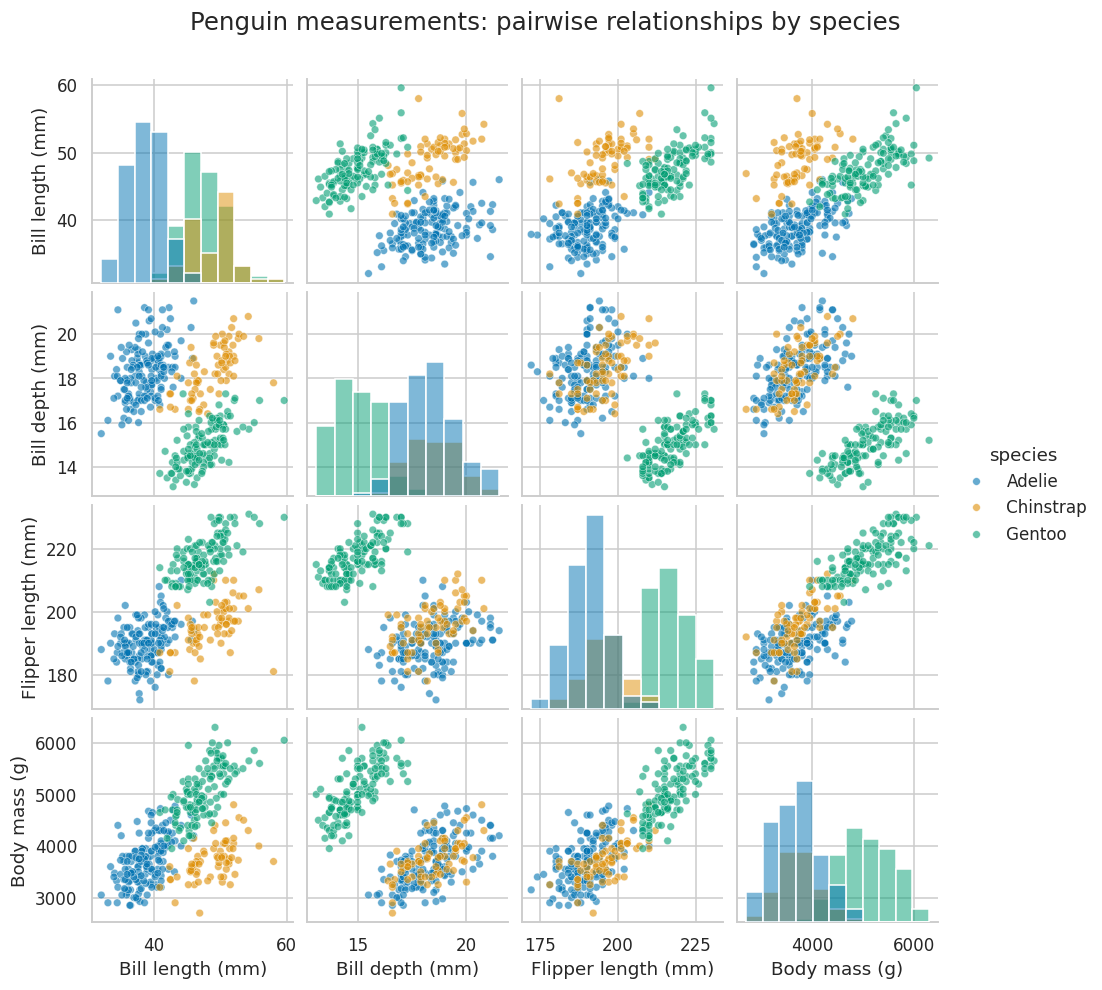

In [14]:
measurements = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]
pair_data = penguins.dropna(subset=measurements + ["species"])
g = sns.pairplot(pair_data, vars=measurements, hue="species", palette="colorblind",
                 diag_kind="hist", plot_kws={"alpha": 0.6, "s": 25}, height=2.2)
nice_labels = ["Bill length (mm)", "Bill depth (mm)", "Flipper length (mm)", "Body mass (g)"]
for i, label in enumerate(nice_labels):
    g.axes[-1, i].set_xlabel(label)
    g.axes[i, 0].set_ylabel(label)
g.fig.suptitle("Penguin measurements: pairwise relationships by species", y=1.02, fontsize=16)
g.fig.subplots_adjust(top=0.95)
plt.show()

**What does this chart tell us?**

1. Gentoo penguins usually have both greater body mass and longer flippers than the other species.
2. Adelie penguins tend to have shorter bills than Chinstrap and Gentoo penguins.
3. Flipper length and body mass show a positive relationship, while species overlap in some other measurement pairs; several features together separate them more clearly.

## 7. Faceted regression — bills and tips

Dataset: tips. Split by time and smoker; apply a custom theme. Use total bill as the explanatory x variable and tip as y.

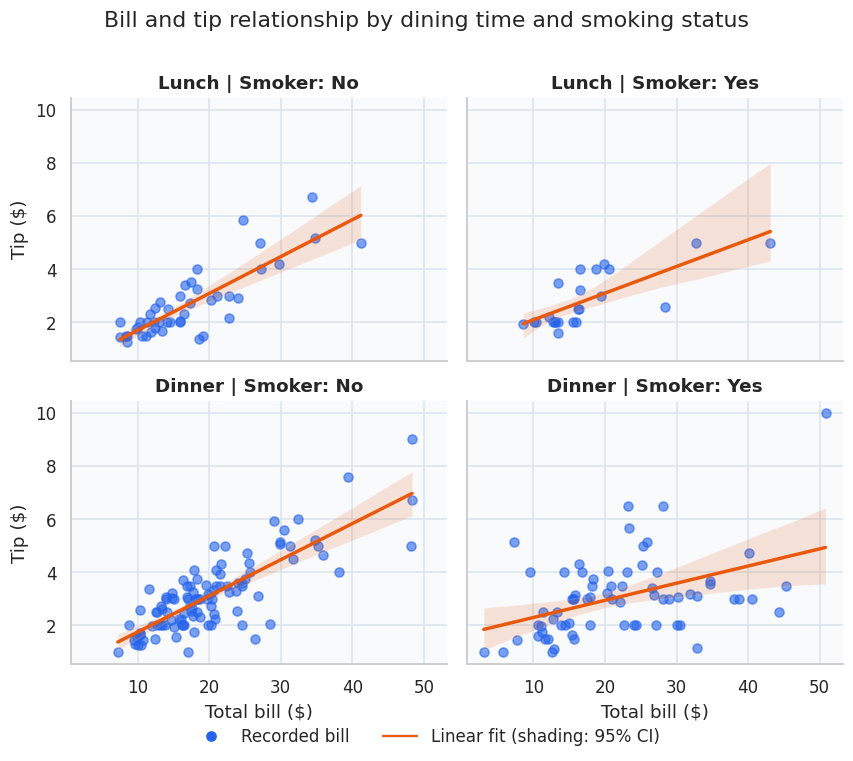

In [15]:
sns.set_theme(style="whitegrid", context="notebook",
              rc={"axes.facecolor": "#f8fafc", "grid.color": "#dbe3ed", "axes.titleweight": "bold"})
g = sns.lmplot(data=tips, x="total_bill", y="tip", row="time", col="smoker",
               row_order=["Lunch", "Dinner"], col_order=["No", "Yes"],
               height=3.3, aspect=1.2, ci=95, seed=18,
               scatter_kws={"alpha": 0.6, "s": 35, "color": "#2563eb"},
               line_kws={"color": "#ea580c"})
g.set_axis_labels("Total bill ($)", "Tip ($)")
g.set_titles(row_template="{row_name}", col_template="Smoker: {col_name}")
g.fig.suptitle("Bill and tip relationship by dining time and smoking status", y=1.03)
legend_items = [Line2D([0], [0], marker="o", linestyle="", color="#2563eb", label="Recorded bill"),
                Line2D([0], [0], color="#ea580c", label="Linear fit (shading: 95% CI)")]
g.fig.legend(handles=legend_items, loc="lower center", ncol=2, frameon=False)
g.fig.subplots_adjust(bottom=0.13, top=0.91)
plt.show()

**What does this chart tell us?**

Larger bills generally receive larger tips in the four groups, but there is considerable variation around the fitted lines. Different slopes across panels are descriptive and do not prove that smoking status or dining time causes a change in tipping.